<div style="padding:22px 26px; border-radius:14px; background:linear-gradient(135deg,#7A0019,#9E1B32); color:white; margin-bottom:18px;">
  <div style="font-size:30px; font-weight:700; line-height:1.2;">CS4343 HW2: Custom Convolutional Neural Network with PyTorch</div>
  <div style="font-size:16px; margin-top:7px; opacity:0.95;">Due Date: Sept 22, 2026, 11:59 pm · 100 Points</div>
</div>

The objective of this homework is to implement and train a **custom CNN** for image classification using **PyTorch**. You will build reusable `nn.Module` components, combine them into a custom CNN with skip connections, and train the model on **CIFAR-10**.

You may use PyTorch for tensors, automatic differentiation, optimization, and data loading. Do **not** use a prebuilt model from `torchvision.models` for the required network.

Before submission, restart the kernel and run the notebook from the first cell to the last cell. Complete every location marked `YOUR CODE HERE`.

In [ ]:
NAME = "Daijiro Tanimura"


## Assignment Overview

CIFAR-10 contains color images with shape

$$
x \in \mathbb{R}^{3\times 32\times 32}
$$

and **10 object classes**. The training set contains 50,000 images and the test set contains 10,000 images. In this assignment, 5,000 images from the original training set are reserved for validation.

Your network will use the following architecture:

| Component | Structure | Output Size |
|:--|:--|:--|
| Stem | $3\times3$ Conv, 32 channels, BatchNorm, ReLU | $32\times32\times32$ |
| Stage 1 | 2 skip-connection blocks, 32 channels | $32\times32\times32$ |
| Stage 2 | 2 skip-connection blocks, 64 channels; first block uses stride 2 | $64\times16\times16$ |
| Stage 3 | 2 skip-connection blocks, 128 channels; first block uses stride 2 | $128\times8\times8$ |
| Pooling | Global average pooling | $128\times1\times1$ |
| Classifier | Linear layer | 10 logits |

For a skip-connection block, the main computation is

$$
Y = \operatorname{ReLU}\!\left(F(X)+S(X)\right),
$$

where $F(X)$ is the two-convolution main path and $S(X)$ is the shortcut path. The shortcut is the identity mapping if the input and output shapes agree. If the number of channels or spatial resolution changes, the shortcut uses a $1\times1$ convolution followed by Batch Normalization so that the two paths have matching shapes before addition.

### Grading

The required components are graded out of **100 points**. An additional **5 points of extra credit** are available through the Short Analysis Questions.

| Section | Topic | Points |
|:--|:--|--:|
| 1 | CIFAR-10 data pipeline and augmentation | 15 |
| 2 | Reusable convolution module | 10 |
| 3 | Skip-connection block | 25 |
| 4 | Custom CNN and initialization | 25 |
| 5 | Training, evaluation, and hyperparameter tuning | 25 |
|  | **Required Total** | **100** |
|  | **Short Analysis Questions — Extra Credit** | **+5** |
|  | **Maximum Possible Score** | **105 / 100** |

## Setup and Imports

In [ ]:
# Install all packages required by this notebook.
%pip install -q torch torchvision matplotlib


In [1]:
import copy
import random

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Device:", DEVICE)

CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)


Device: cpu


# 1. CIFAR-10 Data Pipeline and Augmentation — 15 Points

## Training and Evaluation Transforms — 5 Points

Images in the training set should be augmented before normalization. Implement `build_transforms()` with the following operations.

For the **training transform**, use this order:

1. `RandomCrop(32, padding=4)`
2. `RandomHorizontalFlip()`
3. `ToTensor()`
4. `Normalize(CIFAR10_MEAN, CIFAR10_STD)`

For the **validation and test transform**, do not use random augmentation. Use only:

1. `ToTensor()`
2. `Normalize(CIFAR10_MEAN, CIFAR10_STD)`

Return the two composed transforms as `train_transform, eval_transform`.

In [2]:
def build_transforms():
    # Step 1: Build the training transform using random crop and horizontal flip.
    # Step 2: Convert training images to tensors.
    # Step 3: Normalize training tensors using CIFAR10_MEAN and CIFAR10_STD.
    # Step 4: Build the evaluation transform without random augmentation.
    # Step 5: Return train_transform and eval_transform.

    # YOUR CODE HERE
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    ])
    eval_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    ])
    return train_transform, eval_transform


In [3]:
# Test build_transforms
_train_transform, _eval_transform = build_transforms()
assert isinstance(_train_transform, transforms.Compose)
assert isinstance(_eval_transform, transforms.Compose)
assert len(_train_transform.transforms) == 4
assert len(_eval_transform.transforms) == 2


## Train/Validation/Test DataLoaders — 10 Points

Implement `make_cifar10_loaders()`.

The original CIFAR-10 training set contains 50,000 images. Create one reproducible random split using `seed`:

$$
45{,}000\text{ training images} \qquad 5{,}000\text{ validation images}.
$$

The training subset must use the augmented transform. The validation subset must use the evaluation transform. The official test set must also use the evaluation transform.

Use PyTorch's `DataLoader` for minibatching. Shuffle the training loader only.

In [4]:
def make_cifar10_loaders(
    root="./data",
    batch_size=128,
    val_size=5000,
    num_workers=0,
    seed=42,
):
    # Step 1: Obtain train_transform and eval_transform from build_transforms().
    # Step 2: Create two copies of the CIFAR-10 training dataset:
    #         one with train_transform and one with eval_transform.
    # Step 3: Create the CIFAR-10 test dataset with eval_transform.
    # Step 4: Use torch.randperm with a seeded torch.Generator to create shuffled indices.
    # Step 5: Use the first val_size indices for validation and the rest for training.
    # Step 6: Wrap the augmented training copy and evaluation training copy with Subset.
    # Step 7: Create train, validation, and test DataLoaders.
    #         Shuffle only the training loader.
    # Step 8: Return train_loader, val_loader, and test_loader.

    # YOUR CODE HERE
    train_transform, eval_transform = build_transforms()
    full_train_aug  = datasets.CIFAR10(root, train=True, download=True, transform=train_transform)
    full_train_eval = datasets.CIFAR10(root, train=True, download=True, transform=eval_transform)
    test_dataset = datasets.CIFAR10(root, train=False, download=True, transform=eval_transform)
    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(full_train_aug), generator=generator)

    val_indices = indices[:val_size]
    train_indices = indices[val_size:]

    train_subset = Subset(full_train_aug, train_indices)
    val_subset   = Subset(full_train_eval, val_indices)

    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_loader   = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    return train_loader, val_loader, test_loader


In [5]:
train_loader, val_loader, test_loader = make_cifar10_loaders(
    batch_size=128,
    val_size=5000,
    num_workers=0,
    seed=SEED,
)

print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))
print("Test samples:", len(test_loader.dataset))

assert len(train_loader.dataset) == 45000
assert len(val_loader.dataset) == 5000
assert len(test_loader.dataset) == 10000

X_batch, y_batch = next(iter(train_loader))
assert X_batch.ndim == 4 and X_batch.shape[1:] == (3, 32, 32)
assert y_batch.ndim == 1
print("One minibatch:", X_batch.shape, y_batch.shape)


c:\Users\tanim\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training samples: 45000
Validation samples: 5000
Test samples: 10000
One minibatch: torch.Size([128, 3, 32, 32]) torch.Size([128])


## Visualize a Training Minibatch

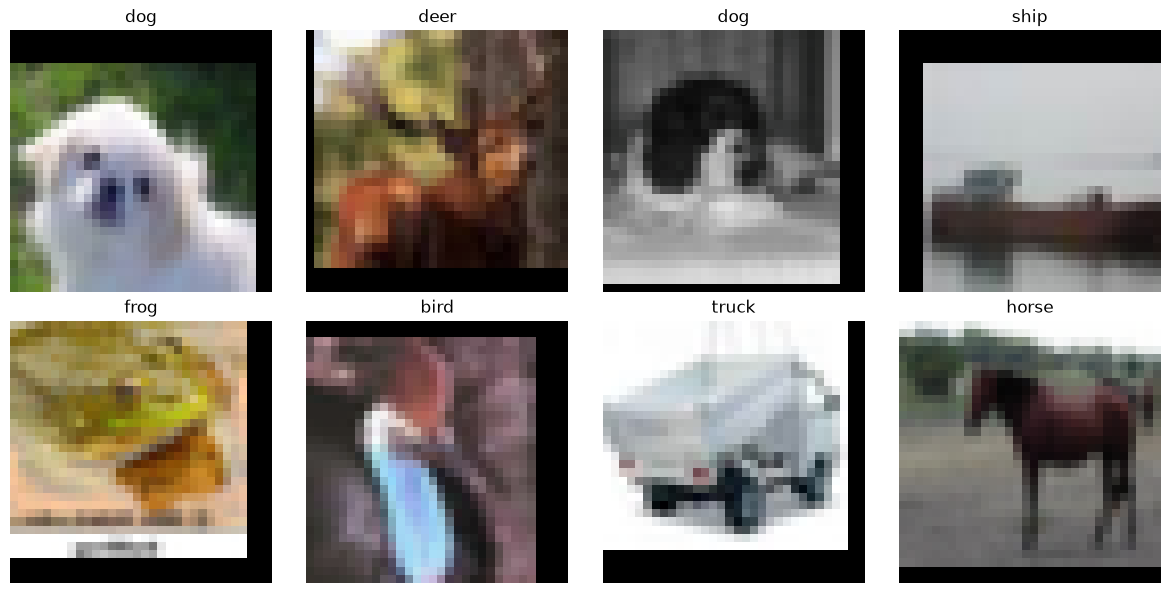

In [6]:
def denormalize_image(x):
    mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR10_STD).view(3, 1, 1)
    return torch.clamp(x.cpu() * std + mean, 0.0, 1.0)

images, labels = next(iter(train_loader))
class_names = train_loader.dataset.dataset.classes

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    image = denormalize_image(images[i]).permute(1, 2, 0).numpy()
    plt.imshow(image)
    plt.title(class_names[int(labels[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()


# 2. Reusable Convolution Module — 10 Points

## Implement `ConvBNReLU`

PyTorch models are built by subclassing `nn.Module`. Your first custom module will combine three operations:

$$
X
\longrightarrow
\operatorname{Conv2d}
\longrightarrow
\operatorname{BatchNorm2d}
\longrightarrow
\operatorname{ReLU}.
$$

Use `bias=False` in the convolution because Batch Normalization already contains a learnable shift parameter.

In [7]:
class ConvBNReLU(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        stride=1,
        padding=1,
    ):
        super().__init__()

        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        # Step 1: Apply the convolution.
        # Step 2: Apply Batch Normalization.
        # Step 3: Apply ReLU.
        # Step 4: Return the resulting tensor.

        # YOUR CODE HERE
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return x


In [8]:
# Test ConvBNReLU
_block = ConvBNReLU(3, 32, kernel_size=3, stride=1, padding=1)
_x = torch.randn(4, 3, 32, 32)
_y = _block(_x)
assert _y.shape == (4, 32, 32, 32)
assert isinstance(_block, nn.Module)
assert isinstance(_block.conv, nn.Conv2d)
assert isinstance(_block.bn, nn.BatchNorm2d)
assert isinstance(_block.relu, nn.ReLU)


# 3. Skip-Connection Block — 25 Points

## Implement `SkipConnectionBlock`

The main path of the block is

$$
X
\rightarrow
\text{Conv-BN-ReLU}
\rightarrow
\text{Conv-BN}
\rightarrow
F(X).
$$

The shortcut path is

$$
S(X)=
\begin{cases}
X, & \text{if the input and output shapes match},\\
\operatorname{BN}\!\left(\operatorname{Conv}_{1\times1}(X)\right),
& \text{otherwise}.
\end{cases}
$$

The final block output is

$$
Y=\operatorname{ReLU}\!\left(F(X)+S(X)\right).
$$

A projection shortcut is required if `stride != 1` or `in_channels != out_channels`. The $1\times1$ shortcut convolution must use the same `stride` as the first convolution on the main path.

In [9]:
class SkipConnectionBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        # Step 1: Create the first main-path operation using ConvBNReLU.
        #         It maps in_channels -> out_channels and uses the supplied stride.
        # Step 2: Create the second 3x3 convolution.
        #         It keeps out_channels channels, uses stride=1, padding=1, and bias=False.
        # Step 3: Create BatchNorm2d after the second convolution.
        # Step 4: If stride == 1 and in_channels == out_channels, use nn.Identity()
        #         for the shortcut.
        # Step 5: Otherwise, use a 1x1 Conv2d followed by BatchNorm2d for the shortcut.
        # Step 6: Create the final ReLU.

        # YOUR CODE HERE
        self.conv1 = ConvBNReLU(in_channels, out_channels,
                                 kernel_size=3, stride=stride, padding=1)
        self.conv2 = nn.Conv2d(out_channels, out_channels,
                                kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride == 1 and in_channels == out_channels:
            self.shortcut = nn.Identity()
        else:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        # Step 1: Compute the shortcut output from x.
        # Step 2: Pass x through the first main-path module.
        # Step 3: Apply the second convolution and its BatchNorm.
        # Step 4: Add the main path and shortcut tensors.
        # Step 5: Apply the final ReLU.
        # Step 6: Return the block output.

        # YOUR CODE HERE
        identity = self.shortcut(x)
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.bn2(out)
        out = out + identity
        out = self.relu(out)
        return out


In [10]:
# Test SkipConnectionBlock
_same = SkipConnectionBlock(32, 32, stride=1)
_x_same = torch.randn(4, 32, 32, 32)
_y_same = _same(_x_same)
assert _y_same.shape == (4, 32, 32, 32)
assert isinstance(_same.shortcut, nn.Identity)

_down = SkipConnectionBlock(32, 64, stride=2)
_x_down = torch.randn(4, 32, 32, 32)
_y_down = _down(_x_down)
assert _y_down.shape == (4, 64, 16, 16)
assert isinstance(_down.shortcut, nn.Sequential)


# 4. Custom CNN and Initialization — 25 Points

## Implement `CustomCNN` — 20 Points

Construct the network from the assignment overview. Each stage contains exactly **two** skip-connection blocks.

- Stage 1 keeps 32 channels and keeps the spatial size unchanged.
- Stage 2 changes 32 channels to 64 channels. Its first skip-connection block uses stride 2.
- Stage 3 changes 64 channels to 128 channels. Its first skip-connection block uses stride 2.

After Stage 3, use `nn.AdaptiveAvgPool2d((1, 1))`. Flatten the pooled tensor and use one `nn.Linear` layer to produce 10 logits.

Do not apply softmax inside the model. `nn.CrossEntropyLoss` expects raw logits.

In [11]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Step 1: Create the stem: ConvBNReLU(3, 32, kernel_size=3, stride=1, padding=1).
        # Step 2: Create Stage 1 with two 32 -> 32 skip-connection blocks.
        # Step 3: Create Stage 2. The first block is 32 -> 64 with stride=2;
        #         the second is 64 -> 64 with stride=1.
        # Step 4: Create Stage 3. The first block is 64 -> 128 with stride=2;
        #         the second is 128 -> 128 with stride=1.
        # Step 5: Create adaptive average pooling to output spatial size 1x1.
        # Step 6: Create the final Linear layer from 128 features to num_classes logits.

        # YOUR CODE HERE
        super().__init__()
        self.stem = ConvBNReLU(3, 32, kernel_size=3, stride=1, padding=1)

        self.stage1 = nn.Sequential(
            SkipConnectionBlock(32, 32, stride=1),
            SkipConnectionBlock(32, 32, stride=1),
        )
        self.stage2 = nn.Sequential(
            SkipConnectionBlock(32, 64, stride=2),
            SkipConnectionBlock(64, 64, stride=1),
        )
        self.stage3 = nn.Sequential(
            SkipConnectionBlock(64, 128, stride=2),
            SkipConnectionBlock(128, 128, stride=1),
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        # Step 1: Pass x through the stem.
        # Step 2: Pass the result through Stage 1, Stage 2, and Stage 3.
        # Step 3: Apply global average pooling.
        # Step 4: Flatten all dimensions except the batch dimension.
        # Step 5: Apply the final Linear layer.
        # Step 6: Return the logits.

        # YOUR CODE HERE
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)   # (N, 128, 1, 1) -> (N, 128)
        x = self.fc(x)
        return x


In [12]:
# Test CustomCNN
_model_test = CustomCNN(num_classes=10)
_logits = _model_test(torch.randn(8, 3, 32, 32))
assert _logits.shape == (8, 10)

_num_params = sum(p.numel() for p in _model_test.parameters())
print(f"Trainable parameters: {_num_params:,}")
assert 600_000 < _num_params < 800_000


Trainable parameters: 696,618


## He Initialization — 5 Points

Initialize the model explicitly using PyTorch's initialization utilities.

For each `nn.Conv2d`, use He normal initialization appropriate for ReLU:

```python
nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
```

For each `nn.BatchNorm2d`, initialize the scale to 1 and shift to 0. For each `nn.Linear`, initialize the weights with a normal distribution having standard deviation $0.01$ and initialize the bias to 0.

In [13]:
def initialize_weights(module):
    # Step 1: If module is nn.Conv2d, apply He normal initialization.
    # Step 2: If module is nn.BatchNorm2d, set weight to 1 and bias to 0.
    # Step 3: If module is nn.Linear, initialize weight ~ N(0, 0.01^2) and bias to 0.
    # Step 4: This function does not need to return anything.

    # YOUR CODE HERE
    if isinstance(module, nn.Conv2d):
        nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.constant_(module.weight, 1.0)
        nn.init.constant_(module.bias, 0.0)
    elif isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.01)
        nn.init.constant_(module.bias, 0.0)


In [14]:
# Test initialization helper
_init_test = CustomCNN(num_classes=10)
_init_test.apply(initialize_weights)

for module in _init_test.modules():
    if isinstance(module, nn.BatchNorm2d):
        assert torch.allclose(module.weight.detach(), torch.ones_like(module.weight))
        assert torch.allclose(module.bias.detach(), torch.zeros_like(module.bias))

assert torch.allclose(_init_test.fc.bias.detach(), torch.zeros_like(_init_test.fc.bias))


# 5. Training, Evaluation, and Hyperparameter Tuning — 25 Points

## Training Setup

Use cross-entropy loss and SGD with momentum:

$$
\theta_{t+1}
=
\theta_t-\alpha v_{t+1},
\qquad
v_{t+1}=\mu v_t+\nabla_\theta J(\theta_t).
$$

The training function will use

- `torch.optim.SGD`,
- momentum $\mu=0.9$,
- Nesterov momentum,
- weight decay, and
- `CosineAnnealingLR` for the learning-rate schedule.

The test set must not be used during hyperparameter selection.

## One Training Epoch — 8 Points

In [15]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    # Step 1: Put the model in training mode with model.train().
    # Step 2: Initialize accumulators for total loss, correct predictions, and sample count.
    # Step 3: Loop over minibatches from loader.
    # Step 4: Move images and labels to device.
    # Step 5: Clear old gradients with optimizer.zero_grad().
    # Step 6: Run the forward pass and compute the loss.
    # Step 7: Call loss.backward().
    # Step 8: Call optimizer.step().
    # Step 9: Accumulate loss weighted by minibatch size and count correct predictions.
    # Step 10: Return average loss and accuracy over the entire loader.

    # YOUR CODE HERE
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


## Evaluation — 5 Points

In [16]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    # Step 1: Put the model in evaluation mode with model.eval().
    # Step 2: Initialize accumulators for total loss, correct predictions, and sample count.
    # Step 3: Loop over loader and move each minibatch to device.
    # Step 4: Compute logits and loss. Do not call backward().
    # Step 5: Accumulate loss and correct predictions.
    # Step 6: Return average loss and accuracy.

    # YOUR CODE HERE
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


## Full Training Function — 5 Points

In [17]:
def fit_model(
    model,
    train_loader,
    val_loader,
    lr=0.1,
    weight_decay=5e-4,
    epochs=20,
    device=DEVICE,
    verbose=True,
):
    # Step 1: Move model to device.
    # Step 2: Create nn.CrossEntropyLoss().
    # Step 3: Create torch.optim.SGD with momentum=0.9, nesterov=True,
    #         the supplied learning rate, and the supplied weight decay.
    # Step 4: Create CosineAnnealingLR with T_max=epochs.
    # Step 5: Create a history dictionary for train/validation loss and accuracy and lr.
    # Step 6: For each epoch:
    #         a. call train_one_epoch,
    #         b. call evaluate on the validation loader,
    #         c. save a copy of the best model state according to validation accuracy,
    #         d. record all metrics and the current learning rate,
    #         e. call scheduler.step().
    # Step 7: Restore the best validation model weights before returning.
    # Step 8: Return history.

    # YOUR CODE HERE
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                                 nesterov=True, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": [], "lr": []}

    best_val_acc = -1.0
    best_state = None

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion,
                                                  optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if verbose:
            print(f"Epoch {epoch+1}/{epochs} | "
                  f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
                  f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

        scheduler.step()

    model.load_state_dict(best_state)
    return history

In [25]:
# Small synthetic smoke test for the training functions.
# This does not replace CIFAR-10 training; it only checks that the pipeline executes.
_smoke_x = torch.randn(32, 3, 32, 32)
_smoke_y = torch.randint(0, 10, (32,))
_smoke_loader = DataLoader(TensorDataset(_smoke_x, _smoke_y), batch_size=8, shuffle=False)
_smoke_model = CustomCNN(num_classes=10)
_smoke_model.apply(initialize_weights)
_smoke_history = fit_model(
    _smoke_model,
    _smoke_loader,
    _smoke_loader,
    lr=0.01,
    weight_decay=0.0,
    epochs=1,
    device=torch.device("cpu"),
    verbose=False,
)
assert len(_smoke_history["train_loss"]) == 1
assert np.isfinite(_smoke_history["train_loss"][0])


## Hyperparameter Search — 7 Points

Evaluate the four configurations below. Use only a subset of the training and validation data during the search so that the experiment remains manageable. Train each configuration for **4 epochs**.

Tune the initial learning rate $\alpha$ and weight decay $\lambda$:

| Configuration | Learning Rate | Weight Decay |
|:--|--:|--:|
| 1 | 0.03 | $5\times10^{-4}$ |
| 2 | 0.05 | $5\times10^{-4}$ |
| 3 | 0.10 | $5\times10^{-4}$ |
| 4 | 0.10 | $1\times10^{-4}$ |

For each configuration, create a **fresh model**, initialize it, train it, and record the final validation loss and validation accuracy. Select the configuration with the highest validation accuracy and store it in `best_config`.

In [26]:
# Create smaller loaders for hyperparameter tuning.
TUNE_TRAIN_SIZE = min(10000, len(train_loader.dataset))
TUNE_VAL_SIZE = min(2000, len(val_loader.dataset))

_tune_train_dataset = Subset(train_loader.dataset, range(TUNE_TRAIN_SIZE))
_tune_val_dataset = Subset(val_loader.dataset, range(TUNE_VAL_SIZE))

candidate_configs = [
    {"lr": 0.03, "weight_decay": 5e-4},
    {"lr": 0.05, "weight_decay": 5e-4},
    {"lr": 0.10, "weight_decay": 5e-4},
    {"lr": 0.10, "weight_decay": 1e-4},
]

search_results = []

for config in candidate_configs:
    # Step 1: Create tuning DataLoaders with batch_size=128.
    #         Shuffle the tuning training loader only.
    # Step 2: Create a fresh CustomCNN and initialize its weights.
    # Step 3: Train for 2 epochs using config["lr"] and config["weight_decay"].
    # Step 4: Store lr, weight_decay, final val_loss, and final val_acc.

    # YOUR CODE HERE
    tune_train_loader = DataLoader(_tune_train_dataset, batch_size=128, shuffle=True)
    tune_val_loader   = DataLoader(_tune_val_dataset, batch_size=128, shuffle=False)

    model = CustomCNN(num_classes=10)
    model.apply(initialize_weights)

    history = fit_model(
        model, tune_train_loader, tune_val_loader,
        lr=config["lr"], weight_decay=config["weight_decay"],
        epochs=2, device=DEVICE, verbose=False,
    )

    search_results.append({
        "lr": config["lr"],
        "weight_decay": config["weight_decay"],
        "val_loss": history["val_loss"][-1],
        "val_acc": history["val_acc"][-1],
    })

# Step 5: Select the result with the highest validation accuracy.
# YOUR CODE HERE
best_config = max(search_results, key=lambda x: x["val_acc"])
print("Best hyperparameters:", best_config)

Best hyperparameters: {'lr': 0.05, 'weight_decay': 0.0005, 'val_loss': 1.4896259746551515, 'val_acc': 0.429}


## Final Training

Use the best learning rate and weight decay from the search to train a fresh CustomCNN on the full training set. The cell below trains the final model for **50 epochs**. This longer schedule gives the CNN enough time to learn strong CIFAR-10 features while keeping the experiment manageable on a GPU.

A correct implementation should show a clear improvement in training and validation accuracy over time. Exact accuracy varies with initialization, hardware, and hyperparameters, so evaluation is based on correctness of the implementation and experimental procedure rather than a fixed accuracy threshold.

In [27]:
FINAL_EPOCHS = 50

final_model = CustomCNN(num_classes=10)
final_model.apply(initialize_weights)

final_history = fit_model(
    final_model,
    train_loader,
    val_loader,
    lr=float(best_config["lr"]),
    weight_decay=float(best_config["weight_decay"]),
    epochs=FINAL_EPOCHS,
    device=DEVICE,
    verbose=True,
)


Epoch 1/50 | train_loss=1.4742 train_acc=0.4497 | val_loss=1.4619 val_acc=0.5292
Epoch 2/50 | train_loss=0.9767 train_acc=0.6515 | val_loss=0.9370 val_acc=0.6708
Epoch 3/50 | train_loss=0.7854 train_acc=0.7229 | val_loss=0.8033 val_acc=0.7356
Epoch 4/50 | train_loss=0.6728 train_acc=0.7659 | val_loss=0.9239 val_acc=0.6800
Epoch 5/50 | train_loss=0.5998 train_acc=0.7916 | val_loss=0.7506 val_acc=0.7490
Epoch 6/50 | train_loss=0.5458 train_acc=0.8113 | val_loss=0.7382 val_acc=0.7536
Epoch 7/50 | train_loss=0.5106 train_acc=0.8234 | val_loss=0.5369 val_acc=0.8140
Epoch 8/50 | train_loss=0.4740 train_acc=0.8359 | val_loss=0.7558 val_acc=0.7656
Epoch 9/50 | train_loss=0.4465 train_acc=0.8470 | val_loss=0.6199 val_acc=0.7952
Epoch 10/50 | train_loss=0.4206 train_acc=0.8562 | val_loss=0.5508 val_acc=0.8150
Epoch 11/50 | train_loss=0.4041 train_acc=0.8609 | val_loss=0.5784 val_acc=0.8156
Epoch 12/50 | train_loss=0.3887 train_acc=0.8655 | val_loss=0.5258 val_acc=0.8214
Epoch 13/50 | train_loss=

## Training Curves

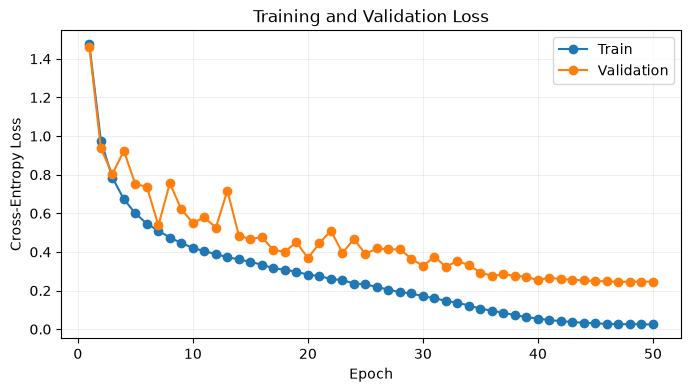

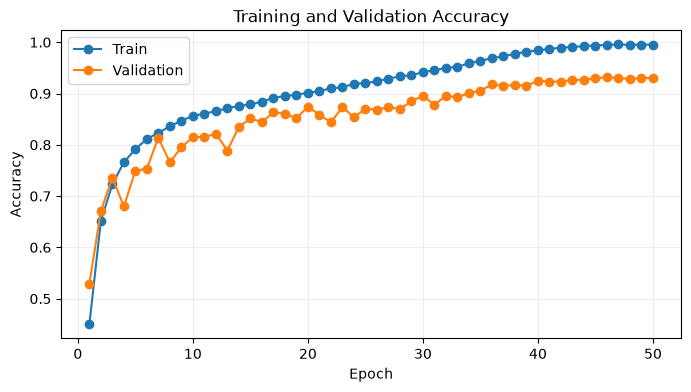

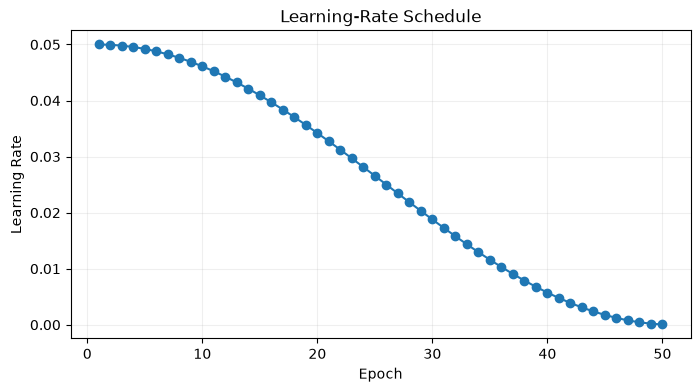

In [28]:
def plot_history(history):
    epochs = np.arange(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(8, 4))
    plt.plot(epochs, history["train_loss"], marker="o", label="Train")
    plt.plot(epochs, history["val_loss"], marker="o", label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(epochs, history["train_acc"], marker="o", label="Train")
    plt.plot(epochs, history["val_acc"], marker="o", label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training and Validation Accuracy")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(epochs, history["lr"], marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Learning Rate")
    plt.title("Learning-Rate Schedule")
    plt.grid(alpha=0.2)
    plt.show()

plot_history(final_history)


## Final Test-Set Evaluation

In [29]:
criterion = nn.CrossEntropyLoss()
test_loss, test_acc = evaluate(final_model, test_loader, criterion, DEVICE)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {100 * test_acc:.2f}%")


Test loss: 0.2726
Test accuracy: 92.06%


## Short Analysis Questions — +5 Extra Credit

These questions are optional. Answer each in **2–4 sentences**.

1. Stage 2 and Stage 3 use a $1\times1$ convolution in the shortcut of their first skip-connection block. Why can the identity shortcut not be used in those blocks?
2. State the spatial size and number of channels after the stem, Stage 1, Stage 2, and Stage 3. What operation causes each reduction in spatial resolution?
3. Why does this network use global average pooling before the final linear classifier instead of flattening the entire $128\times8\times8$ feature map directly into a large fully connected layer?
4. Which hyperparameter configuration achieved the highest validation accuracy? Briefly describe how learning rate and weight decay affected the validation results you observed.

## Submission Checklist

- Restart the kernel and run all cells from top to bottom.
- Confirm that every provided test cell passes.
- Keep the hyperparameter-search output and final training curves in the notebook.
- Report the final CIFAR-10 test loss and accuracy.
- Complete the Short Analysis Questions only if you want the optional extra credit.
- Submit the completed `.ipynb` file.